<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [2]:
import sys
sys.path.append('..')  # adjust if library lives elsewhere

import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from copy import deepcopy
from itertools import product
from typing import Callable
from tqdm import tqdm

from PIL import Image, ImageDraw
from scipy.stats import wilcoxon

#Functions
from triangle_sol import TriangleSolution

<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

In [3]:
# configuration
IMAGE_PATH   = 'girl_pearl_earing.png'  
IMG_WIDTH    = 300
IMG_HEIGHT   = 400
N_TRIANGLES  = 100

Image loaded: (300, 400) — array shape (400, 300, 4)


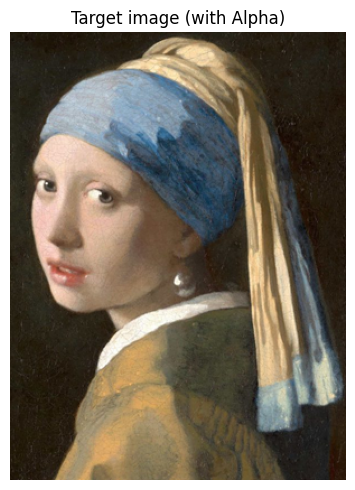

In [4]:
# load image
target_image = Image.open(IMAGE_PATH).convert('RGBA').resize((IMG_WIDTH, IMG_HEIGHT)) 
TARGET_ARRAY = np.array(target_image, dtype=np.float32)  # shape (400, 300, 3)
TriangleSolution.target_array = TARGET_ARRAY

print(f'Image loaded: {target_image.size} — array shape {TARGET_ARRAY.shape}')

plt.figure(figsize=(4, 5))
# Matplotlib handles RGBA arrays natively
plt.imshow(TARGET_ARRAY / 255.0 if TARGET_ARRAY.max() > 1.0 else TARGET_ARRAY)
plt.title('Target image (with Alpha)')
plt.axis('off')
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)


<span style="color:#BA8E23;">

**TEXT ABOVE INSPIRED IN PRATICAL CLASS 3**

</span>

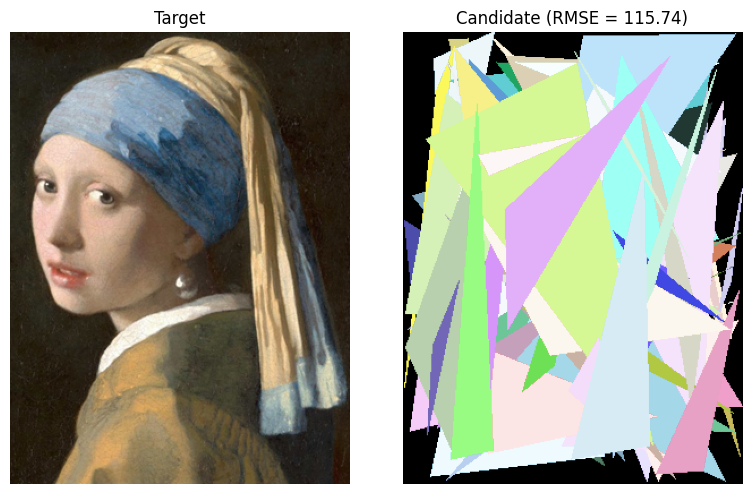

In [5]:
sol = TriangleSolution(
    n_triangles=N_TRIANGLES,
    img_width=IMG_WIDTH,
    img_height=IMG_HEIGHT,
    target_array=TARGET_ARRAY
)

sol.show()

The output generated is a **single random individual**.

<h2 id="chapter4" style="color:#89AC76;">4. Genetic Algorithm</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

This chapter defines the GA operators and the main evolution loop. All operators are implemented as standalone functions so they can be swapped independently — this is intentional, as the challenge (Section X) requires isolating the contribution of individual components.

<h3 id="chapter4.1" style="color:#89AC76;">4.1 Selection</h3>

Two selection methods are implemented and compared:

**Roulette wheel** assigns selection probability proportional to inverted fitness (since this is minimisation). It gives strongly fit individuals a large share of selections, which can accelerate convergence but risks premature loss of diversity.

**Rank-based** assigns probability proportional to rank rather than raw fitness value. This dampens the dominance of very fit individuals — particularly desirable here because the fitness landscape is deceptive and diversity must be maintained to escape local optima.

In [6]:
def roulette_wheel_selection(population):
    """
    Fitness-proportionate selection (roulette wheel).

    Because this is a minimisation problem, fitness values are inverted before
    computing selection probabilities: individuals with lower RMSE receive a
    proportionally higher chance of being selected.
    """
    fitnesses = np.array([ind.fitness() for ind in population])
    inverted  = 1.0 / (fitnesses + 1e-8)
    probs     = inverted / inverted.sum()
    idx       = np.random.choice(len(population), p=probs)
    return population[idx]


def rank_based_selection(population):
    """
    Rank-based selection.

    Individuals are ranked by fitness (rank 1 = worst, rank N = best).
    Selection probability is proportional to rank, which reduces the
    dominance of very fit individuals and preserves diversity.
    """
    n          = len(population)
    sorted_pop = sorted(population, key=lambda ind: ind.fitness(), reverse=True)
    ranks      = np.arange(1, n + 1, dtype=float)
    probs      = ranks / ranks.sum()
    idx        = np.random.choice(n, p=probs)
    return sorted_pop[idx]

<h3 id="chapter4.2" style="color:#89AC76;">4.2 Crossover</h3>

**1-point whole-triangle crossover** places the crossover point at a triangle boundary (a multiple of 10), so genes belonging to the same triangle are never split across parents. This is a deliberate design choice: splitting a triangle mid-gene (e.g. inheriting vertices from one parent and colour from another) would destroy the geometric coherence of that triangle and introduce destructive noise.

In [7]:
def one_point_crossover(parent1, parent2, crossover_rate=0.9):
    """
    1-point whole-triangle crossover.

    The crossover point is chosen at a triangle boundary (multiple of 10),
    so genes belonging to the same triangle are never split across parents.
    If crossover does not fire, both parents are returned as deep copies.
    """
    if random.random() > crossover_rate:
        return deepcopy(parent1), deepcopy(parent2)

    n_tri = len(parent1.representation) // 10
    point = random.randint(1, n_tri - 1) * 10

    r1 = parent1.representation[:point] + parent2.representation[point:]
    r2 = parent2.representation[:point] + parent1.representation[point:]

    return TriangleSolution(r1), TriangleSolution(r2)

<h3 id="chapter4.3" style="color:#89AC76;">4.3 Mutation</h3>

**Gaussian mutation** perturbs each gene independently with probability `mutation_rate`. Vertex genes receive small perturbations (low $\sigma$) to nudge triangle positions; colour genes use a larger $\sigma$ to allow broader colour exploration. All values are clipped to their valid domains after perturbation.

In [8]:
def gaussian_mutation(individual, mutation_rate=0.01, sigma_vertex=0.05, sigma_colour=10):
    """
    Per-gene Gaussian mutation.

    Each gene is perturbed independently with probability `mutation_rate`:
      - Vertex genes  (positions 0–5 within triangle): noise ~ N(0, sigma_vertex), clipped to [0, 1].
      - Colour genes  (positions 6–9 within triangle): noise ~ N(0, sigma_colour), clipped to [0, 255].
    Assigning to individual.representation triggers fitness cache invalidation.
    """
    rep = individual.representation[:]

    for i in range(len(rep)):
        if random.random() < mutation_rate:
            gene_pos = i % 10
            if gene_pos < 6:
                rep[i] = float(np.clip(rep[i] + random.gauss(0, sigma_vertex), 0.0, 1.0))
            else:
                rep[i] = float(np.clip(rep[i] + random.gauss(0, sigma_colour), 0, 255))

    individual.representation = rep
    return individual

<h3 id="chapter4.4" style="color:#89AC76;">4.4 GA Loop</h3>


In [9]:
def genetic_algorithm(
    population_size  = 50,
    n_generations    = 500,
    selection_method = 'rank',     # 'rank' | 'roulette'
    crossover_rate   = 0.9,
    mutation_rate    = 0.01,
    sigma_vertex     = 0.05,
    sigma_colour     = 10,
    elitism_n        = 2,
    verbose          = True,
    verbose_every    = 50,
):
    """
    Generational GA for the triangle image approximation problem.

    Each generation:
      1. Carry `elitism_n` best individuals unchanged to the next generation.
      2. Fill remaining slots: select two parents → crossover → mutate.
      3. Replace population.

    Returns
    -------
    best        : TriangleSolution  — best individual found
    history     : list[float]       — best RMSE per generation
    avg_history : list[float]       — average RMSE per generation
    """
    select = rank_based_selection if selection_method == 'rank' else roulette_wheel_selection

    population      = [TriangleSolution() for _ in range(population_size)]
    history         = []
    avg_history     = []

    for gen in range(n_generations):

        population.sort()  # ascending RMSE — best at index 0

        best_fitness = population[0].fitness()
        avg_fitness  = float(np.mean([ind.fitness() for ind in population]))
        history.append(best_fitness)
        avg_history.append(avg_fitness)

        if verbose and (gen % verbose_every == 0 or gen == n_generations - 1):
            print(f"Gen {gen:>4d} | best RMSE: {best_fitness:.4f} | avg RMSE: {avg_fitness:.4f}")

        # build next generation
        next_gen = [deepcopy(ind) for ind in population[:elitism_n]]

        while len(next_gen) < population_size:
            p1 = select(population)
            p2 = select(population)

            o1, o2 = one_point_crossover(p1, p2, crossover_rate)
            gaussian_mutation(o1, mutation_rate, sigma_vertex, sigma_colour)
            gaussian_mutation(o2, mutation_rate, sigma_vertex, sigma_colour)

            next_gen.append(o1)
            if len(next_gen) < population_size:
                next_gen.append(o2)

        population = next_gen

    population.sort()
    best = population[0]

    if verbose:
        print(f"\nFinished. Best RMSE: {best.fitness():.4f}")

    return best, history, avg_history

#### Plotting utility 

In [10]:
def plot_fitness_history(history, avg_history=None, title='GA — fitness over generations'):
    """Plots best (and optionally average) RMSE per generation."""
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(history, label='Best RMSE', linewidth=1.5)
    if avg_history:
        ax.plot(avg_history, label='Avg RMSE', linewidth=1, linestyle='--', alpha=0.7)
    ax.set_xlabel('Generation')
    ax.set_ylabel('RMSE')
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [11]:
best, history, avg_history = genetic_algorithm(
    population_size  = 50,
    n_generations    = 500,
    selection_method = 'rank',
    crossover_rate   = 0.9,
    mutation_rate    = 0.01,
    sigma_vertex     = 0.05,
    sigma_colour     = 10,
    elitism_n        = 2,
    verbose          = True,
    verbose_every    = 50,
)

Gen    0 | best RMSE: 89.5095 | avg RMSE: 104.6530
Gen   50 | best RMSE: 68.3390 | avg RMSE: 69.4910
Gen  100 | best RMSE: 61.0686 | avg RMSE: 61.6997
Gen  150 | best RMSE: 55.8096 | avg RMSE: 56.5202
Gen  200 | best RMSE: 52.1708 | avg RMSE: 52.6330
Gen  250 | best RMSE: 49.6756 | avg RMSE: 50.1418
Gen  300 | best RMSE: 48.0161 | avg RMSE: 48.5616
Gen  350 | best RMSE: 46.7556 | avg RMSE: 47.1952
Gen  400 | best RMSE: 45.6416 | avg RMSE: 46.1471
Gen  450 | best RMSE: 44.3985 | avg RMSE: 44.7354
Gen  499 | best RMSE: 43.6620 | avg RMSE: 44.0499

Finished. Best RMSE: 43.6609


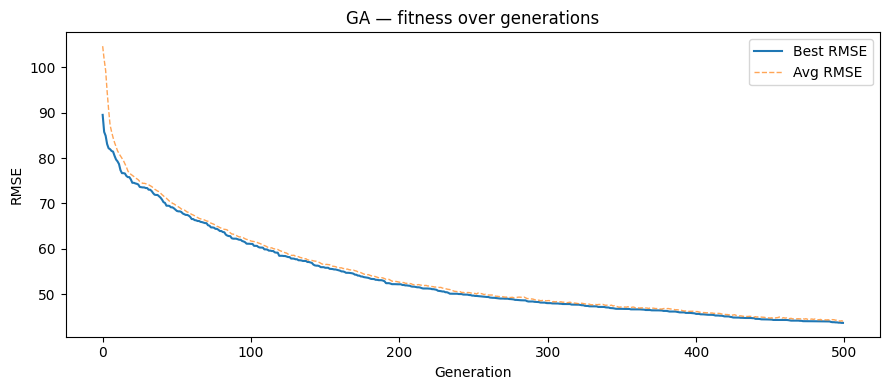

In [12]:
plot_fitness_history(history, avg_history)

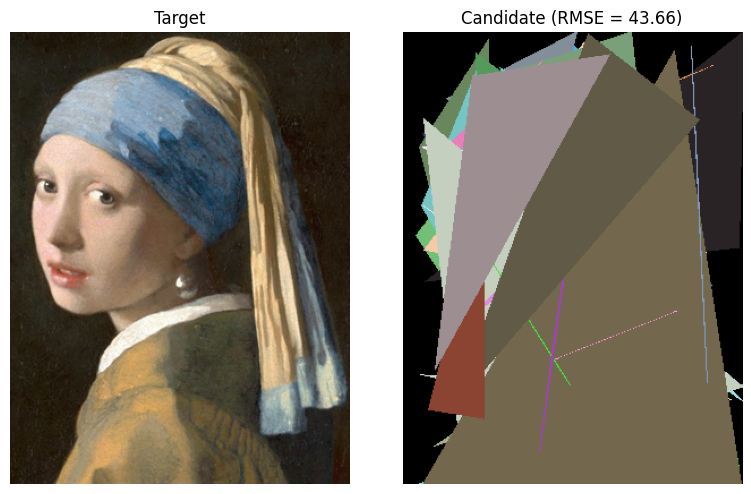

In [13]:
best.show()

<h3 id="chapter4.4" style="color:#89AC76;">4.4 GA Loop with Grid Search</h3>

In [14]:
#  Define the grid search
GRID = {
    'population_size'  : [20, 50, 100],
    'mutation_rate'    : [0.005, 0.01, 0.05],
    'crossover_rate'   : [0.7, 0.9, 1.0],
    'selection_method' : ['rank', 'roulette'],
}

GS_GENERATIONS = 500   # generations per run
GS_REPEATS     = 5     # independent runs per combination

# Fixed params
GS_FIXED = dict(
    sigma_vertex = 0.05,
    sigma_colour = 10,
    elitism_n    = 2,
    verbose      = False,
)

In [15]:
#  Grid search runner
def run_grid_search(grid, gs_generations, gs_repeats, fixed_params):
    """
    Exhaustive grid search over GA hyperparameters.

    For each combination of parameters in `grid`, the GA is run
    `gs_repeats` times. The mean and std of the best RMSE across
    repeats are recorded. Results are returned sorted by mean RMSE
    (ascending — lower is better).

    Parameters
    ----------
    grid          : dict[str, list]  — parameter name → list of values to try
    gs_generations: int              — number of generations per run
    gs_repeats    : int              — independent runs per combination
    fixed_params  : dict             — parameters held constant

    Returns
    -------
    results : list[dict] — each entry has 'params', 'mean_rmse', 'std_rmse', 'all_rmse'
    """
    keys   = list(grid.keys())
    values = list(grid.values())
    combos = list(product(*values))   # cartesian product

    print(f"Grid search: {len(combos)} combinations × {gs_repeats} repeats "
          f"= {len(combos) * gs_repeats} total runs\n")

    results = []

    for combo in tqdm(combos, desc='Grid search'):
        params = dict(zip(keys, combo))

        run_rmses = []
        for _ in range(gs_repeats):
            best_sol, _, _ = genetic_algorithm(
                n_generations = gs_generations,
                **params,
                **fixed_params,
            )
            run_rmses.append(best_sol.fitness())

        results.append({
            'params'    : params,
            'mean_rmse' : float(np.mean(run_rmses)),
            'std_rmse'  : float(np.std(run_rmses)),
            'all_rmse'  : run_rmses,
        })

    # sort best to worst
    results.sort(key=lambda x: x['mean_rmse'])
    return results

In [16]:
#  Results display helpers
def print_grid_search_results(results, top_n=10):
    """Prints a ranked table of the top_n combinations."""
    print(f"{'Rank':<5} {'Mean RMSE':>10} {'Std':>8}   Parameters")
    print("-" * 70)
    for rank, r in enumerate(results[:top_n], 1):
        param_str = ", ".join(f"{k}={v}" for k, v in r['params'].items())
        print(f"{rank:<5} {r['mean_rmse']:>10.4f} {r['std_rmse']:>8.4f}   {param_str}")


def plot_grid_search_results(results, top_n=15):
    """Bar chart of mean RMSE for the top_n combinations."""
    top     = results[:top_n]
    labels  = ["\n".join(f"{k}={v}" for k, v in r['params'].items()) for r in top]
    means   = [r['mean_rmse'] for r in top]
    stds    = [r['std_rmse']  for r in top]

    fig, ax = plt.subplots(figsize=(max(10, top_n * 0.9), 5))
    bars = ax.bar(range(top_n), means, yerr=stds, capsize=4,
                  color='#89AC76', edgecolor='black', linewidth=0.6)
    ax.set_xticks(range(top_n))
    ax.set_xticklabels(labels, fontsize=7)
    ax.set_ylabel('Mean RMSE')
    ax.set_title(f'Grid Search — Top {top_n} Combinations')
    ax.bar_label(bars, fmt='%.3f', fontsize=7, padding=3)
    plt.tight_layout()
    plt.show()

Grid search: 54 combinations × 5 repeats = 270 total runs



Grid search: 100%|██████████| 54/54 [11:27:35<00:00, 763.99s/it]   


Rank   Mean RMSE      Std   Parameters
----------------------------------------------------------------------
1        40.0667   1.3687   population_size=100, mutation_rate=0.01, crossover_rate=1.0, selection_method=rank
2        40.1549   2.0258   population_size=100, mutation_rate=0.005, crossover_rate=1.0, selection_method=rank
3        40.8752   1.1895   population_size=100, mutation_rate=0.01, crossover_rate=0.9, selection_method=rank
4        41.6288   1.4953   population_size=100, mutation_rate=0.01, crossover_rate=0.7, selection_method=rank
5        42.0555   2.5585   population_size=100, mutation_rate=0.05, crossover_rate=0.9, selection_method=rank
6        42.3616   0.9350   population_size=100, mutation_rate=0.005, crossover_rate=0.9, selection_method=rank
7        42.3692   2.1501   population_size=100, mutation_rate=0.05, crossover_rate=1.0, selection_method=rank
8        42.5066   0.9186   population_size=100, mutation_rate=0.005, crossover_rate=0.7, selection_method=rank

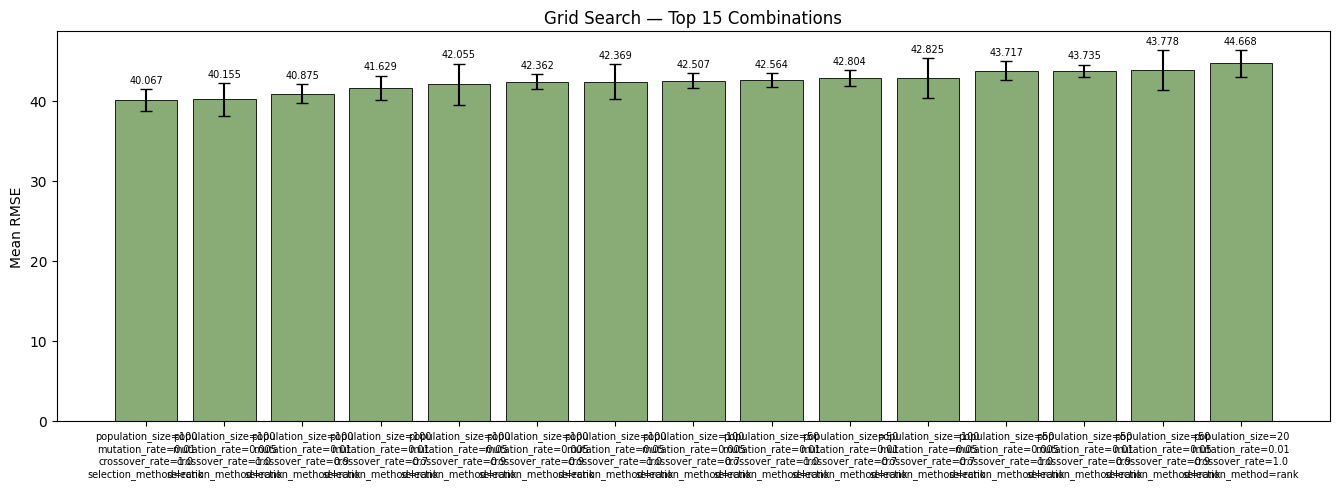

In [17]:
gs_results = run_grid_search(
    grid          = GRID,
    gs_generations= GS_GENERATIONS,
    gs_repeats    = GS_REPEATS,
    fixed_params  = GS_FIXED,
)

print_grid_search_results(gs_results, top_n=10)
plot_grid_search_results(gs_results, top_n=15)

Best parameters found: {'population_size': 100, 'mutation_rate': 0.01, 'crossover_rate': 1.0, 'selection_method': 'rank'}
Gen    0 | best RMSE: 88.0246 | avg RMSE: 106.2418
Gen   50 | best RMSE: 66.9751 | avg RMSE: 68.0497
Gen  100 | best RMSE: 58.8417 | avg RMSE: 59.5410
Gen  150 | best RMSE: 53.0480 | avg RMSE: 54.0205
Gen  200 | best RMSE: 48.6971 | avg RMSE: 49.2126
Gen  250 | best RMSE: 45.7720 | avg RMSE: 46.2994
Gen  300 | best RMSE: 44.2661 | avg RMSE: 44.6511
Gen  350 | best RMSE: 42.8623 | avg RMSE: 43.2523
Gen  400 | best RMSE: 42.1045 | avg RMSE: 42.4211
Gen  450 | best RMSE: 41.4361 | avg RMSE: 41.8042
Gen  499 | best RMSE: 41.0468 | avg RMSE: 41.3348

Finished. Best RMSE: 41.0339


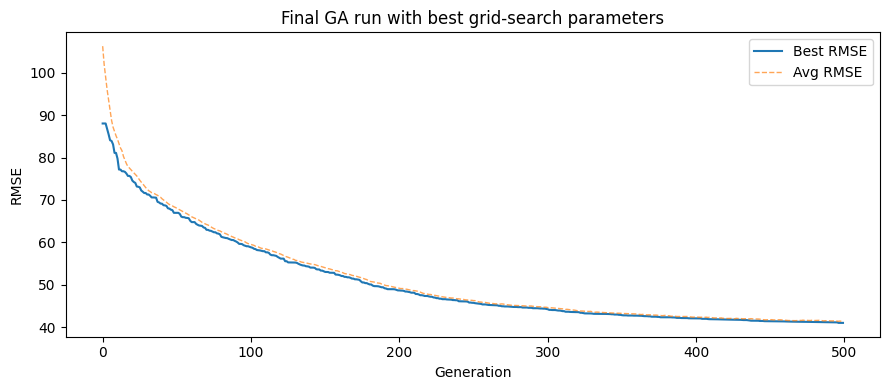

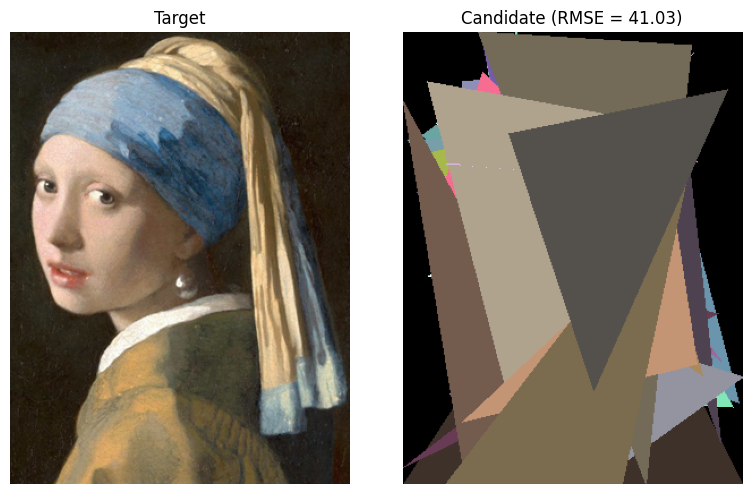

In [18]:
# Final run with best parameters found
best_params = gs_results[0]['params']
print("Best parameters found:", best_params)

best_final, history_final, avg_history_final = genetic_algorithm(
    n_generations = 500,          
    **best_params,
    **{k: v for k, v in GS_FIXED.items() if k != 'verbose'},  # exclude verbose from GS_FIXED
    verbose       = True,
    verbose_every = 50,
)


plot_fitness_history(history_final, avg_history_final,
                     title='Final GA run with best grid-search parameters')
best_final.show()


<span style="color:#BA8E23;">

### <h1><strong>Next Steps</strong></h1>

### <h3><strong>TOP PRIORITY</strong></h3>
1. **Parallel fitness evaluation**
This will allow:
	- larger populations
	- more generations
	- more grid search runs
Which directly improves quality.

2. **Hybrid GA + Local Search (Hill Climbing or CMA-ES)**
	- ran Hill Climbing as a local search after the GA converged, using the GA's best solution as the starting point.

3. **Adaptive mutation**
Static mutation is a bottleneck.
Use:
	- high mutation early
	- low mutation late
	- per‑triangle mutation rates

4. **Triangle‑level operators** (over gene-level mutation)
Mutating triangles as units preserves structure and accelerates convergence.

5. **Multiple operators per category** 
	- 3 selection methods (2 - WHICH IS APPLIED NOW !!)
	- 3 crossover operators (1)
	- 3 mutation operators (1)



### <h3><strong>MEDIUM PRIORITY</strong></h3>
6. **Novelty or diversity preservation**
Avoids premature convergence.

7. **Smarter initialization**
Start with:
	- background‑colored triangles - BIAS????
	- triangles placed roughly in regions matching the target
	This reduces search difficulty dramatically

### <h3><strong>LOWER PRIORITY</strong></h3>
8. **Wilcoxon statistical tests with a tournament structure**<br>
Use Wilcoxon signed-rank tests to determine which configuration was statistically significantly better, then ran a tournament-style elimination comparing the winner sequentially against challengers.

9. **Improve "search space size" cell**<br>
Calculating the search space size for triangle configurations (continuous, so you'd frame it differently — e.g. "at 64-bit float precision, the gene space has X distinct points"). It shows problem awareness.

10. **Add Operator demonstration cells**<br>
After defining each operator, they showed it running on an example and printed before/after fitness values. 

</span>